# Diagnosing Customer Satisfaction in E-Commerce: A SQL Analysis

### Olist's marketplace lives and dies on review scores — they drive seller reputation, marketplace trust, and (weakly) repeat business. This project uses SQL to identify which operational factors — delivery performance, product category, payment friction, geography, seller behavior — are actually associated with customer satisfaction (review score), versus factors that only look important without evidence. A secondary check examines repeat-purchase behavior (~3% of customers) as a minor finding, reported honestly given its small sample size rather than treated as the project's spine.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import os

In [2]:
DATA_DIR = "data/"
conn = sqlite3.connect("olist.db")
cursor = conn.cursor()
print("Database connected")

Database connected


In [3]:
# Map of CSV filename -> table name
csv_to_table = {
    "olist_orders_dataset.csv": "orders",
    "olist_order_items_dataset.csv": "order_items",
    "olist_customers_dataset.csv": "customers",
    "olist_products_dataset.csv": "products",
    "olist_sellers_dataset.csv": "sellers",
    "olist_order_payments_dataset.csv": "payments",
    "olist_order_reviews_dataset.csv": "reviews",
    "olist_geolocation_dataset.csv": "geolocation",
    "product_category_name_translation.csv": "category_translation",
}

for csv_file, table_name in csv_to_table.items():
    path = os.path.join(DATA_DIR, csv_file)
    df = pd.read_csv(path)
    df.to_sql(table_name, conn, if_exists="replace", index=False)
    print(f"{table_name}: {len(df):,} rows loaded")

orders: 99,441 rows loaded
order_items: 112,650 rows loaded
customers: 99,441 rows loaded
products: 32,951 rows loaded
sellers: 3,095 rows loaded
payments: 103,886 rows loaded
reviews: 99,224 rows loaded
geolocation: 1,000,163 rows loaded
category_translation: 71 rows loaded


## Initial Data Quality Investigation

Before any business question is asked, three foundational checks: which customer ID is actually the person-level key, whether the `reviews` table has one row per order, and what the raw tables look like.

In [4]:
query = """
SELECT 
    COUNT(*) AS total_orders,
    COUNT(DISTINCT customer_id) AS unique_customer_ids,
    COUNT(DISTINCT customer_unique_id) AS unique_customer_unique_ids
FROM customers;
"""
pd.read_sql_query(query, conn)

,total_orders,unique_customer_ids,unique_customer_unique_ids
0,99441,99441,96096


`customer_id` is unique per row (order-scoped), while `customer_unique_id` has fewer distinct values — confirming `customer_unique_id` is the real person-level key. Every customer-level query in this project uses `customer_unique_id`, not `customer_id`.

In [5]:
pd.read_sql_query("SELECT * FROM customers LIMIT 5", conn)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [6]:
pd.read_sql_query("SELECT * FROM orders LIMIT 5", conn)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [7]:
pd.read_sql_query("SELECT * FROM order_items LIMIT 5", conn)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [8]:
pd.read_sql_query("SELECT * FROM products LIMIT 5", conn)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [9]:
pd.read_sql_query("SELECT * FROM sellers LIMIT 5", conn)

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [10]:
pd.read_sql_query("SELECT * FROM payments LIMIT 5", conn)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [11]:
pd.read_sql_query("SELECT * FROM reviews LIMIT 5", conn)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,None,None,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,None,None,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,None,None,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,None,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,None,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [12]:
pd.read_sql_query("SELECT * FROM geolocation LIMIT 5", conn)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [13]:
pd.read_sql_query("SELECT * FROM category_translation LIMIT 5", conn)

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


### Repeat-purchase base rate (initial check)

Before committing to a project spine, checked whether "customer retention" had enough variance in this dataset to support a full analysis.

In [14]:
query = """
SELECT customer_unique_id, COUNT(DISTINCT order_id) AS order_count
FROM customers c
JOIN orders o ON c.customer_id = o.customer_id
GROUP BY customer_unique_id
"""
df = pd.read_sql_query(query, conn)
repeat_rate = (df['order_count'] > 1).mean()
print(f"Repeat purchase rate (all order statuses): {repeat_rate:.2%}")

Repeat purchase rate (all order statuses): 3.12%


At ~3%, repeat purchases are too rare to support a full "diagnose retention" project — this reframed the project's spine from retention to **customer satisfaction (review score)**, with repeat-purchase behavior kept as a small, clearly-labeled secondary finding (see final section).

### `reviews` table grain check

Before joining `reviews` to anything, checked whether it's one row per order.

In [15]:
query = """
SELECT order_id, COUNT(*) as cnt
FROM reviews
GROUP BY order_id
HAVING COUNT(*) > 1
"""
dupe_reviews = pd.read_sql_query(query, conn)
print(f"Orders with more than one review row: {len(dupe_reviews)}")
dupe_reviews.head()

Orders with more than one review row: 547


,order_id,cnt
0,0035246a40f520710769010f752e7507,2
1,013056cfe49763c6f66bda03396c5ee3,2
2,0176a6846bcb3b0d3aa3116a9a768597,2
3,02355020fd0a40a0d56df9f6ff060413,2
4,029863af4b968de1e5d6a82782e662f5,2


In [16]:
# Inspect one example pair to understand *why* duplicates exist
query = """
SELECT *
FROM reviews
WHERE order_id = 'fe041ba1c9f54016432fa6ee91709dbc'
"""
pd.read_sql_query(query, conn)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,117b4a19af2b247561f0075f73d6eea1,fe041ba1c9f54016432fa6ee91709dbc,5,None,None,2017-12-20 00:00:00,2017-12-20 22:04:37
1,9da0796858da97acd8b67578388a3241,fe041ba1c9f54016432fa6ee91709dbc,5,None,"O cartucho está estourado (vazando), já contat...",2017-12-20 00:00:00,2017-12-20 22:03:18


Investigating a few examples showed these are genuinely separate review submissions (different `review_id`, different comment text) — not a single review edited in place. That raised the question of whether the two rows per order actually agree on `review_score`.

In [17]:
query = """
SELECT r.order_id, COUNT(DISTINCT r.review_score) AS distinct_scores
FROM reviews r
GROUP BY r.order_id
HAVING COUNT(*) > 1
"""
df = pd.read_sql_query(query, conn)
disagree_count = (df['distinct_scores'] > 1).sum()
print(f"Disagree: {disagree_count} / {len(df)} = {disagree_count/len(df):.1%}")

Disagree: 202 / 547 = 36.9%


**36.9% of duplicate-review orders have conflicting scores between the two submissions.** That's too high to treat as a cosmetic resubmission — picking "most recent" or averaging would both be arbitrary, undefendable choices imposed on genuinely ambiguous signal. The chosen fix: **exclude these orders entirely** from the cleaned reviews table, rather than guess which score is "true."

`HAVING COUNT(*) > 1` also needs to catch orders with *more* than 2 review rows, not just exactly 2 — verified below.

In [18]:
# Confirm not all duplicates are simple pairs — some orders have 3 review rows
query = """
SELECT order_id, COUNT(*) as review_count
FROM reviews
GROUP BY order_id
HAVING COUNT(*) > 1
ORDER BY review_count DESC
LIMIT 10
"""
pd.read_sql_query(query, conn)

,order_id,review_count
0,df56136b8031ecd28e200bb18e6ddb2e,3
1,c88b1d1b157a9999ce368f218a407141,3
2,8e17072ec97ce29f0e1f111e598b0c85,3
3,03c939fd7fd3b38f8485a0f95798f1f6,3
4,ffaabba06c9d293a3c614e0515ddbabc,2
5,ff850ba359507b996e8b2fbb26df8d03,2
6,ff763b73e473d03c321bcd5a053316e8,2
7,fe041ba1c9f54016432fa6ee91709dbc,2
8,fd95ae805c63c534f1a64589e102225e,2
9,fd61441ba2a7b57e6342862e779b10b0,2


In [19]:
# Step 1: Create the cleaned reviews view — excludes all orders with more than one review row,
# regardless of whether that order had 2 or 3 duplicate rows
create_view_query = """
CREATE VIEW IF NOT EXISTS reviews_clean AS
SELECT r.*
FROM reviews r
WHERE r.order_id NOT IN (
    SELECT order_id FROM reviews GROUP BY order_id HAVING COUNT(*) > 1
)
"""
conn.execute(create_view_query)
conn.commit()
print("reviews_clean view created.")

reviews_clean view created.


In [20]:
# Step 2: Verify no duplicates remain in the clean view — the property that actually matters,
# independent of how many rows each excluded order originally had
check_query = """
SELECT order_id, COUNT(*) as cnt
FROM reviews_clean
GROUP BY order_id
HAVING COUNT(*) > 1
"""
dupes_remaining = pd.read_sql_query(check_query, conn)
print(f"Duplicate order_ids remaining in reviews_clean: {len(dupes_remaining)}")
# This MUST print 0. If it doesn't, stop and investigate before proceeding.

Duplicate order_ids remaining in reviews_clean: 0


In [21]:
# Step 3: Row-count arithmetic check — computed from actual excluded rows, not assumed pairs
total_reviews = pd.read_sql_query("SELECT COUNT(*) as n FROM reviews", conn)['n'][0]
clean_reviews = pd.read_sql_query("SELECT COUNT(*) as n FROM reviews_clean", conn)['n'][0]

excluded_row_count = pd.read_sql_query("""
    SELECT COUNT(*) as n FROM reviews
    WHERE order_id IN (
        SELECT order_id FROM reviews GROUP BY order_id HAVING COUNT(*) > 1
    )
""", conn)['n'][0]

expected_clean = total_reviews - excluded_row_count

print(f"Total review rows (raw):                   {total_reviews:,}")
print(f"Total review rows (clean):                  {clean_reviews:,}")
print(f"Excluded row count (actual, not assumed):   {excluded_row_count:,}")
print(f"Corrected expected clean count:             {expected_clean:,}")
print(f"Matches actual clean count?                 {expected_clean == clean_reviews}")

Total review rows (raw):                   99,224
Total review rows (clean):                  98,126
Excluded row count (actual, not assumed):   1,098
Corrected expected clean count:             98,126
Matches actual clean count?                 True


**Correction from an earlier pass:** the first version of this check assumed every excluded order had exactly 2 review rows (`excluded_orders * 2`), which produced a 4-row mismatch against the actual clean count. Investigating the mismatch surfaced 4 orders with 3 review rows instead of 2. The exclusion logic (`HAVING COUNT(*) > 1`) already handled this correctly regardless of row count — only the verification arithmetic needed correcting, replaced above with a query that sums actual excluded rows rather than assuming a fixed multiplier.

All satisfaction-related queries from this point on join against `reviews_clean`, never the raw `reviews` table.

## Data Cleaning

### Dtype and date-parseability check

Every downstream query relies on `julianday()` correctly parsing date columns. Confirmed dtypes and, more importantly, that every non-null date value actually parses — an unparseable date silently returns `NULL` from `julianday()` rather than erroring, which would quietly drop rows from any date-based query without warning.

In [22]:
tables = ['orders', 'order_items', 'customers', 'products', 
          'sellers', 'payments', 'reviews_clean']

for table in tables:
    df = pd.read_sql_query(f"SELECT * FROM {table} LIMIT 1000", conn)
    print(f"\n--- {table} ---")
    print(df.dtypes)


--- orders ---
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

--- order_items ---
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
freight_value          float64
dtype: object

--- customers ---
customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object

--- products ---
product_id                     object
product_category_name          object
product_name_lenght           float64
product_description_lenght    float64
product_photos_qty  

In [23]:
for col in ['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']:
    query = f"""
    SELECT COUNT(*) as unparseable
    FROM orders
    WHERE {col} IS NOT NULL AND julianday({col}) IS NULL
    """
    print(col, pd.read_sql_query(query, conn)['unparseable'][0])

query = """
SELECT COUNT(*) as unparseable FROM reviews_clean
WHERE review_creation_date IS NOT NULL AND julianday(review_creation_date) IS NULL
"""
print('review_creation_date', pd.read_sql_query(query, conn)['unparseable'][0])

order_purchase_timestamp 0
order_delivered_customer_date 0
order_estimated_delivery_date 0
review_creation_date 0


All zero — every date column used in this project parses cleanly across all rows. No silently-dropped rows from malformed dates.

### Null audit — every core table, every column

In [24]:
for table in tables:
    df = pd.read_sql_query(f"SELECT * FROM {table}", conn)
    null_counts = df.isnull().sum()
    null_pct = (null_counts / len(df) * 100).round(2)
    result = pd.DataFrame({'nulls': null_counts, 'pct': null_pct})
    result = result[result['nulls'] > 0]  # only show columns with actual nulls
    print(f"\n--- {table} ({len(df):,} rows) ---")
    print(result if not result.empty else "No nulls.")


--- orders (99,441 rows) ---
                               nulls   pct
order_approved_at                160  0.16
order_delivered_carrier_date    1783  1.79
order_delivered_customer_date   2965  2.98

--- order_items (112,650 rows) ---
No nulls.

--- customers (99,441 rows) ---
No nulls.

--- products (32,951 rows) ---
                            nulls   pct
product_category_name         610  1.85
product_name_lenght           610  1.85
product_description_lenght    610  1.85
product_photos_qty            610  1.85
product_weight_g                2  0.01
product_length_cm               2  0.01
product_height_cm               2  0.01
product_width_cm                2  0.01

--- sellers (3,095 rows) ---
No nulls.

--- payments (103,886 rows) ---
No nulls.

--- reviews_clean (98,126 rows) ---
                        nulls    pct
review_comment_title    86592  88.25
review_comment_message  57534  58.63


**Interpretation:**
- `orders.order_delivered_customer_date` nulls (~2.98%) correspond to orders that were never delivered (canceled, unavailable, still in transit) — not missing data, expected given `order_status`. Handled by filtering to `order_status = 'delivered'` in delivery-related queries, not by imputing.
- `products` has 610 rows (1.85%) missing `product_category_name` (and three correlated columns) — these are used in category-level queries, so this needs an explicit fix (below). The dimension/weight columns with 2 nulls are not used anywhere in this project and are left as-is.

### Fixing `product_category_name` nulls

Only `product_category_name` is used in this project's queries — the other null columns in `products` (name/description length, photo count, weight, dimensions) are out of scope and left untouched. The fix is applied via a view, not a destructive `UPDATE`, so the raw `products` table stays an unmodified source of truth.

In [25]:
cursor.execute("""
    CREATE VIEW IF NOT EXISTS products_clean AS
    SELECT
        product_id,
        COALESCE(product_category_name, 'unknown') AS product_category_name,
        product_name_lenght,
        product_description_lenght,
        product_photos_qty,
        product_weight_g,
        product_length_cm,
        product_height_cm,
        product_width_cm
    FROM products
""")
conn.commit()

In [26]:
query = "SELECT product_category_name, COUNT(*) FROM products_clean WHERE product_category_name = 'unknown' GROUP BY 1"
pd.read_sql_query(query, conn)

,product_category_name,COUNT(*)
0,unknown,610


Confirms all 610 previously-null rows now read `'unknown'` in `products_clean`. The raw `products` table still shows 610 nulls if re-audited — that's expected, since the fix lives in the view, not the source table. Every category-level query from here forward joins against `products_clean`.

### Order status distribution

In [27]:
query = """
SELECT order_status, COUNT(*) as cnt,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM orders), 2) as pct
FROM orders
GROUP BY order_status
ORDER BY cnt DESC
"""
pd.read_sql_query(query, conn)

,order_status,cnt,pct
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


97.02% of orders are `delivered`. This is the population every delivery-delay and most satisfaction queries are scoped to — non-delivered orders (2.98%: shipped, canceled, unavailable, invoiced, processing, created, approved) have no meaningful delivery-delay signal and are analyzed separately where relevant (see the order-status-vs-satisfaction query in the Analysis section).

### Full-row duplicate check

In [28]:
for table in tables:
    df = pd.read_sql_query(f"SELECT * FROM {table}", conn)
    dupe_count = df.duplicated().sum()
    print(f"{table}: {dupe_count} fully duplicate rows")

orders: 0 fully duplicate rows
order_items: 0 fully duplicate rows
customers: 0 fully duplicate rows
products: 0 fully duplicate rows
sellers: 0 fully duplicate rows
payments: 0 fully duplicate rows
reviews_clean: 0 fully duplicate rows


Zero full-row duplicates across every table.

### Date sanity — impossible sequences

In [29]:
query = """
SELECT COUNT(*) as impossible_dates
FROM orders
WHERE order_delivered_customer_date IS NOT NULL
  AND order_purchase_timestamp IS NOT NULL
  AND julianday(order_delivered_customer_date) < julianday(order_purchase_timestamp)
"""
pd.read_sql_query(query, conn)

,impossible_dates
0,0


Zero orders delivered before they were purchased. Cleaning is complete: dtypes and dates verified, nulls audited and resolved, no duplicate rows, no impossible dates, review-table grain fixed and verified.

## Exploratory Data Analysis

### Review score distribution

   review_score    cnt
0             1  11286
1             2   3110
2             3   8076
3             4  18949
4             5  56705
   mean_score
0        4.09


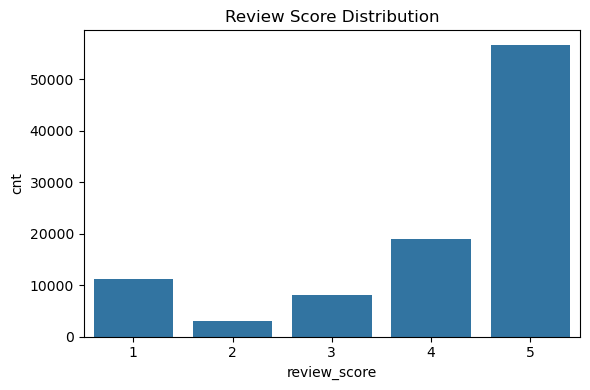

In [30]:
query = "SELECT review_score, COUNT(*) as cnt FROM reviews_clean GROUP BY review_score ORDER BY review_score"
df = pd.read_sql_query(query, conn)
print(df)

mean_query = "SELECT ROUND(AVG(review_score),2) as mean_score FROM reviews_clean"
print(pd.read_sql_query(mean_query, conn))

plt.figure(figsize=(6,4))
sns.barplot(data=df, x='review_score', y='cnt')
plt.title('Review Score Distribution')
plt.tight_layout()
plt.show()

Mean 4.09, heavily skewed toward 5 stars (56,705 of ~98,000 reviews). Because of this skew, every satisfaction query in this project reports **both** the mean score and the percentage of low scores (1-2 stars) — a small shift in the mean can hide a much larger shift in the proportion of genuinely unhappy customers underneath it.

### Delivery delay distribution

This distribution determines the delivery-status bucket cutoffs used throughout the analysis — cutoffs are chosen from the actual shape below, not guessed round numbers.

count    96470.000000
mean       -11.178126
std         10.184354
min       -146.016123
25%        -16.244065
50%        -11.948102
75%         -6.389815
max        188.975081
Name: delay_days, dtype: float64


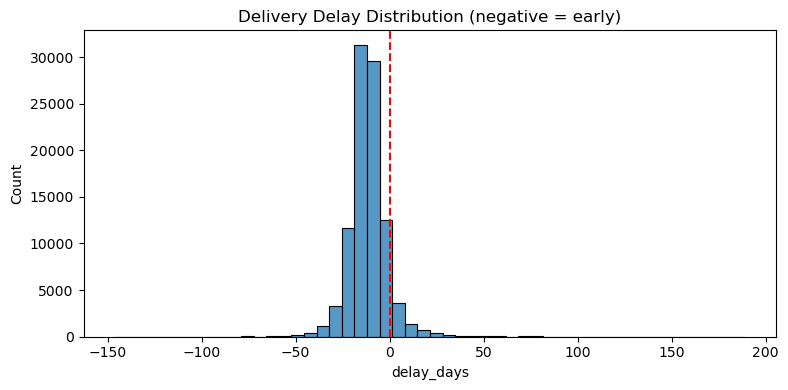

In [31]:
query = """
SELECT order_id,
       julianday(order_delivered_customer_date) - julianday(order_estimated_delivery_date) AS delay_days
FROM orders
WHERE order_status = 'delivered'
  AND order_delivered_customer_date IS NOT NULL
  AND order_estimated_delivery_date IS NOT NULL
"""
delay_df = pd.read_sql_query(query, conn)
print(delay_df['delay_days'].describe())

plt.figure(figsize=(8,4))
sns.histplot(delay_df['delay_days'], bins=50)
plt.axvline(0, color='red', linestyle='--')
plt.title('Delivery Delay Distribution (negative = early)')
plt.tight_layout()
plt.show()

Median delay is **-11.95 days** — most orders arrive well before the estimated date, meaning Olist's estimated-delivery windows are conservatively padded. The 75th percentile is still -6.39 days. This directly informed the delivery-status buckets used in the Analysis section (Early / On time / Late / Very late), rather than an arbitrary 0/7-day guess.

### Outlier check — delay_days and payment_value

Checked via IQR, restricted to the two columns actually used in this project's analysis (not every numeric column in every table — e.g. product dimensions are out of scope and skipped).

In [32]:
def iqr_outliers(df, col):
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(f"{col}: {len(outliers)} outliers ({len(outliers)/len(df)*100:.1f}%), bounds [{lower:.1f}, {upper:.1f}], max={df[col].max()}")

delay_df = pd.read_sql_query("""
    SELECT julianday(order_delivered_customer_date) - julianday(order_estimated_delivery_date) AS delay_days
    FROM orders WHERE order_status = 'delivered'
""", conn)
iqr_outliers(delay_df, 'delay_days')

payment_df = pd.read_sql_query("SELECT payment_value FROM payments", conn)
iqr_outliers(payment_df, 'payment_value')

delay_days: 4871 outliers (5.0%), bounds [-31.0, 8.4], max=188.97508101863787
payment_value: 7981 outliers (7.7%), bounds [-115.8, 344.4], max=13664.08


**`delay_days`: 4,871 outliers (5.0%), upper bound 8.4 days.** This bound closely matches the "Very late (7+ days)" bucket threshold used later — an independent confirmation the bucket cutoff isn't arbitrary. Decision: **keep all outlier rows.** An order 189 days late is not bad data, it's the most extreme version of the exact phenomenon under study (does lateness hurt satisfaction) — dropping it would delete the strongest evidence to make the dataset look tidier.

**`payment_value`: 7,981 outliers (7.7%), upper bound ₹344.4, max ₹13,664.08.** Investigated before deciding whether to drop these.

In [33]:
# Investigate the single largest payment_value
query = """
SELECT order_id, payment_sequential, payment_installments, payment_value
FROM payments
WHERE payment_value = (SELECT MAX(payment_value) FROM payments)
"""
pd.read_sql_query(query, conn)

,order_id,payment_sequential,payment_installments,payment_value
0,03caa2c082116e1d31e67e9ae3700499,1,1,13664.08


In [34]:
# Check whether high-value outliers cluster suspiciously in one installment count (an artifact)
# or spread naturally across installment plans (a real high-value-order pattern)
query = """
SELECT payment_installments, COUNT(*) as cnt,
       ROUND(AVG(payment_value),2) as avg_value
FROM payments
WHERE payment_value > 344.4
GROUP BY payment_installments
ORDER BY cnt DESC
LIMIT 10
"""
pd.read_sql_query(query, conn)

,payment_installments,cnt,avg_value
0,1,2051,687.65
1,10,1875,830.62
2,8,1138,665.72
3,6,555,613.30
4,4,517,599.01
5,3,516,552.16
6,5,513,616.05
7,2,377,557.04
8,7,235,553.46
9,9,106,572.35


The max payment (₹13,664.08) is a single, one-shot, non-installment payment (`payment_installments = 1`) — a genuine high-value transaction, not a summing artifact. The broader outlier set spreads naturally across every installment count with plausible average values (₹550-830) rather than clustering suspiciously — confirming these are real high-value orders, not a data bug. Decision: **keep all outlier rows.**

Worth noting for the payment-friction analysis later: installment count = 10 has the highest average order value (₹830.62) of any bucket — installment count and order value are already visibly correlated here, a confound addressed directly in the payment-friction query below.

Cleaning and EDA are complete. Every finding from this point forward is built on a verified, documented, defensible base.

# ANALYSIS

### Does delivery delay predict customer satisfaction?

Buckets are informed by the delay distribution above (median -12 days, most orders arrive early) rather than a guessed cutoff.

In [35]:
query1 = """
SELECT
    CASE
        WHEN delay_days <= -7 THEN 'Early (7+ days)'
        WHEN delay_days <= 0 THEN 'On time (0-7 days early)'
        WHEN delay_days <= 7 THEN 'Late (1-7 days)'
        ELSE 'Very late (7+ days)'
    END AS delivery_status,
    COUNT(*) AS order_count,
    ROUND(AVG(r.review_score), 2) AS avg_score,
    ROUND(100.0 * SUM(CASE WHEN r.review_score <= 2 THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_low_score
FROM (
    SELECT order_id,
           julianday(order_delivered_customer_date) - julianday(order_estimated_delivery_date) AS delay_days
    FROM orders
    WHERE order_status = 'delivered'
) o
JOIN reviews_clean r ON o.order_id = r.order_id
GROUP BY delivery_status
ORDER BY avg_score DESC
"""
pd.read_sql_query(query1, conn)

,delivery_status,order_count,avg_score,pct_low_score
0,Early (7+ days),70528,4.32,8.96
1,On time (0-7 days early),17149,4.20,10.20
2,Late (1-7 days),4390,3.18,36.08
3,Very late (7+ days),3240,1.73,78.27


**This is the headline finding of the project.** Satisfaction shows a near-perfectly monotonic relationship with delivery delay: 4.32 (early) → 4.20 (on time) → 3.18 (late) → **1.73 (very late)**. Orders delivered more than a week late receive a 1-2 star review **78.27% of the time** — close to a guarantee of a bad review. Early delivery slightly outperforms on-time delivery (4.32 vs 4.20), suggesting customers are actively delighted by arriving well ahead of schedule, not merely neutral about it.

This is a strong association, not a proven causal claim — there was no experiment, and regional or courier-specific confounds (checked further in the geography section) could contribute. But the size and consistency of this effect make it the single most actionable finding in the project: fixing delivery reliability would move satisfaction more than any other factor tested here.

### Does order status itself (independent of delay) predict satisfaction?

Non-delivered orders have no delay_days value at all (no delivery date to compare against). This checks whether just *not being delivered* predicts dissatisfaction, as a complement to the delay-based finding above.

In [36]:
query_status = """
SELECT o.order_status, 
       COUNT(*) as order_count,
       ROUND(AVG(r.review_score), 2) as avg_score,
       ROUND(100.0 * SUM(CASE WHEN r.review_score <= 2 THEN 1 ELSE 0 END) / COUNT(*), 2) as pct_low_score
FROM orders o
JOIN reviews_clean r ON o.order_id = r.order_id
GROUP BY o.order_status
ORDER BY avg_score
"""
pd.read_sql_query(query_status, conn)

,order_status,order_count,avg_score,pct_low_score
0,processing,294,1.27,92.86
1,unavailable,593,1.53,84.82
2,invoiced,305,1.62,82.95
3,canceled,601,1.79,77.04
4,shipped,1021,2.00,69.64
5,created,3,2.33,66.67
6,approved,2,2.50,50.00
7,delivered,95307,4.16,12.79


Independent confirmation of the delay finding: `processing` orders average **1.27** (92.86% low-score), `unavailable` 1.53, `canceled` 1.79 — all catastrophic. `delivered` orders average 4.16 overall. Two unrelated query angles (delay-within-delivered, and status-across-all-orders) point the same direction: failing to get the order to the customer on time or at all is the dominant driver of dissatisfaction in this marketplace.

---

### Are satisfaction problems concentrated in specific product categories and sellers, or spread evenly across the marketplace?

In [37]:
query2a = """
SELECT
    p.product_category_name,
    COUNT(*) AS order_count,
    ROUND(AVG(r.review_score), 2) AS avg_score,
    ROUND(100.0 * SUM(CASE WHEN r.review_score <= 2 THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_low_score
FROM orders o
JOIN order_items oi ON o.order_id = oi.order_id
JOIN products_clean p ON oi.product_id = p.product_id
JOIN reviews_clean r ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
GROUP BY p.product_category_name
HAVING COUNT(*) >= 30
ORDER BY avg_score ASC
LIMIT 15
"""
pd.read_sql_query(query2a, conn)

,product_category_name,order_count,avg_score,pct_low_score
0,fraldas_higiene,37,3.38,21.62
1,moveis_escritorio,1644,3.51,25.61
2,fashion_roupa_masculina,124,3.76,25.00
3,telefonia_fixa,251,3.76,23.11
4,artigos_de_festas,42,3.83,21.43
5,audio,357,3.84,21.29
6,casa_conforto,424,3.86,19.58
7,moveis_colchao_e_estofado,37,3.89,18.92
8,fashion_roupa_feminina,44,3.91,13.64
9,cama_mesa_banho,10677,3.93,18.09


In [38]:
# One order can contain items from multiple categories — check how often, since this
# means category-level order_count won't sum to the total delivered-order count
query = """
SELECT order_id, COUNT(DISTINCT p.product_category_name) as cat_count
FROM order_items oi
JOIN products_clean p ON oi.product_id = p.product_id
GROUP BY order_id
HAVING cat_count > 1
"""
multi_cat = pd.read_sql_query(query, conn)
print(f"Orders spanning multiple categories: {len(multi_cat)} (0.8% of delivered orders)")

Orders spanning multiple categories: 786 (0.8% of delivered orders)


In [39]:
# The n>=30 floor above is too permissive — check the real distribution of category sizes
# before trusting any "worst category" ranking
query = """
SELECT
    p.product_category_name,
    COUNT(*) AS order_count,
    ROUND(AVG(r.review_score), 2) AS avg_score
FROM orders o
JOIN order_items oi ON o.order_id = oi.order_id
JOIN products_clean p ON oi.product_id = p.product_id
JOIN reviews_clean r ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
GROUP BY p.product_category_name
ORDER BY order_count DESC
"""
df = pd.read_sql_query(query, conn)
df['order_count'].describe()

count       74.000000
mean      1469.364865
std       2473.912987
min          2.000000
25%         75.000000
50%        269.500000
75%       1612.250000
max      10677.000000
Name: order_count, dtype: float64

The 25th percentile of category size is 75 orders — meaning a quarter of all 74 categories have fewer than 75 orders each, too thin to trust a ranking. Raised the floor to 100 (just above that 25th-percentile noise threshold) and re-ran.

In [40]:
query2a_v2 = """
SELECT
    p.product_category_name,
    COUNT(*) AS order_count,
    ROUND(AVG(r.review_score), 2) AS avg_score,
    ROUND(100.0 * SUM(CASE WHEN r.review_score <= 2 THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_low_score
FROM orders o
JOIN order_items oi ON o.order_id = oi.order_id
JOIN products_clean p ON oi.product_id = p.product_id
JOIN reviews_clean r ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
GROUP BY p.product_category_name
HAVING COUNT(*) >= 100
ORDER BY avg_score ASC
LIMIT 15
"""
pd.read_sql_query(query2a_v2, conn)

,product_category_name,order_count,avg_score,pct_low_score
0,moveis_escritorio,1644,3.51,25.61
1,fashion_roupa_masculina,124,3.76,25.00
2,telefonia_fixa,251,3.76,23.11
3,audio,357,3.84,21.29
4,casa_conforto,424,3.86,19.58
5,cama_mesa_banho,10677,3.93,18.09
6,moveis_sala,486,3.93,17.08
7,unknown,1517,3.94,19.51
8,casa_construcao,591,3.96,17.43
9,moveis_decoracao,8001,3.96,18.02


**Category finding:** `moveis_escritorio` (office furniture) remains the worst-performing category (avg 3.51, 25.61% low-score) even after raising the size floor to 100+ orders (n=1,644) — this survived the noise-filtering test, so it's a real, stable pattern, not a small-sample artifact. The `unknown` category (the 610 null-category products, fixed earlier) lands mid-pack (avg 3.94) — unremarkable, confirming the null-fill didn't distort or mask anything. Even the worst category (3.51) is far above the 1.73 seen for very-late deliveries — category effects are real but moderate compared to delivery timing.

In [41]:
query = """
SELECT s.seller_id, COUNT(*) as order_count, ROUND(AVG(r.review_score),2) as avg_score
FROM orders o
JOIN order_items oi ON o.order_id = oi.order_id
JOIN sellers s ON oi.seller_id = s.seller_id
JOIN reviews_clean r ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
GROUP BY s.seller_id
"""
df = pd.read_sql_query(query, conn)
df['order_count'].describe()

count    2963.000000
mean       36.696929
std       118.040037
min         1.000000
25%         2.000000
50%         8.000000
75%        25.000000
max      1973.000000
Name: order_count, dtype: float64

Median seller has only 8 delivered orders — far too thin to rank individual sellers broadly. Instead of ranking small sellers directly, grouped sellers into volume tiers first (robust to the small-N problem), then separately ranked only the 230 sellers with 100+ orders, where a ranking is actually defensible.

In [42]:
query2b_tiers = """
SELECT
    CASE
        WHEN order_count <= 5 THEN '1-5 orders'
        WHEN order_count <= 25 THEN '6-25 orders'
        WHEN order_count <= 100 THEN '26-100 orders'
        ELSE '100+ orders'
    END AS seller_tier,
    COUNT(*) AS seller_count,
    SUM(order_count) AS total_orders,
    ROUND(AVG(avg_score), 2) AS avg_of_seller_avgs
FROM (
    SELECT s.seller_id, COUNT(*) as order_count, AVG(r.review_score) as avg_score
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    JOIN sellers s ON oi.seller_id = s.seller_id
    JOIN reviews_clean r ON o.order_id = r.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY s.seller_id
) t
GROUP BY seller_tier
ORDER BY total_orders DESC
"""
pd.read_sql_query(query2b_tiers, conn)

,seller_tier,seller_count,total_orders,avg_of_seller_avgs
0,100+ orders,230,67388,4.06
1,26-100 orders,510,26365,4.14
2,6-25 orders,977,12065,4.15
3,1-5 orders,1246,2915,4.17


A small, monotonic pattern: large sellers (100+ orders) average 4.06 vs. 4.17 for tiny sellers (1-5 orders). Cross-checked at the review level (rather than averaging each seller's average equally) to rule out an averaging artifact:

In [43]:
query2b_review_level = """
SELECT
    CASE
        WHEN order_count <= 5 THEN '1-5 orders'
        WHEN order_count <= 25 THEN '6-25 orders'
        WHEN order_count <= 100 THEN '26-100 orders'
        ELSE '100+ orders'
    END AS seller_tier,
    review_score
FROM (
    SELECT s.seller_id, o.order_id, r.review_score,
           COUNT(*) OVER (PARTITION BY s.seller_id) as order_count
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    JOIN sellers s ON oi.seller_id = s.seller_id
    JOIN reviews_clean r ON o.order_id = r.order_id
    WHERE o.order_status = 'delivered'
) t
"""
df = pd.read_sql_query(query2b_review_level, conn)
df.groupby('seller_tier')['review_score'].agg(['mean', 'count']).round(3)

,mean,count
seller_tier,,
1-5 orders,4.148,2915
100+ orders,4.049,67388
26-100 orders,4.135,26365
6-25 orders,4.143,12065


Nearly identical to the seller-level tier averages — confirms the pattern is real, not an artifact of unweighted averaging. Given 230 sellers clear the 100+ order threshold, ranked individual worst-performing high-volume sellers directly:

In [44]:
query2b_worst_sellers = """
SELECT s.seller_id, COUNT(*) as order_count, ROUND(AVG(r.review_score),2) as avg_score,
       ROUND(100.0 * SUM(CASE WHEN r.review_score <= 2 THEN 1 ELSE 0 END) / COUNT(*), 2) as pct_low_score
FROM orders o
JOIN order_items oi ON o.order_id = oi.order_id
JOIN sellers s ON oi.seller_id = s.seller_id
JOIN reviews_clean r ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
GROUP BY s.seller_id
HAVING COUNT(*) >= 100
ORDER BY avg_score ASC
LIMIT 10
"""
pd.read_sql_query(query2b_worst_sellers, conn)

,seller_id,order_count,avg_score,pct_low_score
0,1ca7077d890b907f89be8c954a02686a,126,2.27,63.49
1,2eb70248d66e0e3ef83659f71b244378,193,2.81,47.67
2,8e6d7754bc7e0f22c96d255ebda59eba,126,2.94,46.03
3,a49928bcdf77c55c6d6e05e09a9b4ca5,104,2.97,43.27
4,8444e55c1f13cd5c179851e5ca5ebd00,102,3.16,38.24
5,7c67e1448b00f6e969d365cea6b010ab,1336,3.34,29.57
6,88460e8ebdecbfecb5f9601833981930,290,3.38,31.72
7,b2479f944e1b90cf8a5de1bbfde284d6,125,3.38,32.80
8,710e3548e02bc1d2831dfc4f1b5b14d4,136,3.46,30.15
9,897060da8b9a21f655304d50fd935913,405,3.47,29.63


The worst seller (n=126) averages **2.27**, with 63.49% low-score reviews — a real, distinct outlier, not tail-of-distribution noise. Tested whether these specific bad sellers explain the whole tier-level effect found above:

In [45]:
# Does removing the clearly underperforming large sellers (avg < 3.5) close the tier gap?
query = """
SELECT ROUND(AVG(review_score), 3) as avg_excl_worst, COUNT(*) as n
FROM (
    SELECT s.seller_id, r.review_score
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    JOIN sellers s ON oi.seller_id = s.seller_id
    JOIN reviews_clean r ON o.order_id = r.order_id
    WHERE o.order_status = 'delivered'
) t
WHERE seller_id NOT IN (
    SELECT seller_id FROM (
        SELECT s.seller_id, COUNT(*) as cnt, AVG(r.review_score) as avg_s
        FROM orders o
        JOIN order_items oi ON o.order_id = oi.order_id
        JOIN sellers s ON oi.seller_id = s.seller_id
        JOIN reviews_clean r ON o.order_id = r.order_id
        WHERE o.order_status = 'delivered'
        GROUP BY s.seller_id
        HAVING cnt >= 100
    ) WHERE avg_s < 3.5
)
"""
pd.read_sql_query(query, conn)

,avg_excl_worst,n
0,4.106,105790


**Correction from the first-glance interpretation:** excluding just the handful of clearly underperforming large sellers (avg < 3.5) raises the remaining "100+ orders" average from 4.05 to **4.11** — nearly matching the small-seller tiers. The apparent "scale hurts satisfaction" pattern is not structural; it's driven by a small number of specific sellers with real, sustained service problems (one alone, n=1,336, averages 3.34 with 29.6% low-score reviews). This reframes a vague trend into an actionable one: audit and address these specific sellers rather than treating scale itself as the cause.

**Answering the business question:** if Olist's ops team has limited time, **sellers, not categories, is where to focus.** Category-level dissatisfaction is real but diffuse — hard to "fix" a whole product category. Seller-level dissatisfaction is concentrated and identifiable: a short, specific list of named sellers (worst: 2.27 avg, 63.49% low-score) responsible for a disproportionate share of bad experiences — a list that can be acted on directly (audit, retrain, or delist).

---

### Does customer location predict satisfaction, independent of delivery delay?

In [46]:
query3a = """
SELECT
    c.customer_state,
    COUNT(*) AS order_count,
    ROUND(AVG(r.review_score), 2) AS avg_score,
    ROUND(100.0 * SUM(CASE WHEN r.review_score <= 2 THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_low_score
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
JOIN reviews_clean r ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
GROUP BY c.customer_state
ORDER BY order_count DESC
"""
df = pd.read_sql_query(query3a, conn)
df

,customer_state,order_count,avg_score,pct_low_score
0,SP,40063,4.25,10.66
1,RJ,12142,3.97,18.29
2,MG,11217,4.19,11.75
3,RS,5291,4.19,11.93
4,PR,4881,4.24,10.84
5,SC,3505,4.14,12.92
6,BA,3212,3.93,17.03
7,DF,2051,4.14,13.16
8,ES,1960,4.08,13.83
9,GO,1929,4.11,13.22


In [47]:
df['order_count'].describe()

count       27.000000
mean      3529.888889
std       7932.078515
min         41.000000
25%        362.000000
50%        876.000000
75%       2631.500000
max      40063.000000
Name: order_count, dtype: float64

State order counts range from 41 to 40,063 — no threshold applied at this stage since the goal is to compare against delay, not rank states outright; small states are treated with appropriate caution in the interpretation below.

In [48]:
query3b = """
SELECT
    c.customer_state,
    CASE
        WHEN delay_days <= 0 THEN 'On time or early'
        ELSE 'Late'
    END AS delivery_status,
    COUNT(*) AS order_count,
    ROUND(AVG(r.review_score), 2) AS avg_score
FROM (
    SELECT o.order_id, o.customer_id,
           julianday(o.order_delivered_customer_date) - julianday(o.order_estimated_delivery_date) AS delay_days
    FROM orders o
    WHERE o.order_status = 'delivered'
) o
JOIN customers c ON o.customer_id = c.customer_id
JOIN reviews_clean r ON o.order_id = r.order_id
GROUP BY c.customer_state, delivery_status
HAVING order_count >= 30
ORDER BY c.customer_state, delivery_status
"""
pd.read_sql_query(query3b, conn)

,customer_state,delivery_status,order_count,avg_score
0,AC,On time or early,77,4.18
1,AL,Late,91,2.34
2,AL,On time or early,299,4.33
3,AM,On time or early,137,4.33
4,AP,On time or early,63,4.22
5,BA,Late,439,2.56
6,BA,On time or early,2773,4.15
7,CE,Late,193,2.20
8,CE,On time or early,1077,4.26
9,DF,Late,145,2.40


**Customer location does not independently predict satisfaction.** When delivery is on time, review scores cluster tightly across all states (4.15-4.40) — location itself barely matters. States that looked worse overall in the raw ranking, like Rio de Janeiro (3.97 avg) and Bahia (3.93 avg), turned out to simply have higher late-delivery rates (RJ: 13.3% vs. SP: 5.9%) rather than genuinely unhappier customers — once split by delivery status, RJ's on-time score (4.25) is unremarkable and in line with the rest of the country.

The one real regional effect: **how badly a late delivery is received varies meaningfully by state** (late-order avg scores range from 1.94 to 3.20) — a secondary, more tentative finding, since several states have thin sample sizes in the late bucket.

Note: this "Late" bucket (any delay > 0 days) is broader than query 1's more granular buckets (1-7 vs 7+ days) — the two aren't directly comparable row-for-row, though both point the same direction. Business takeaway: geography isn't a lever worth targeting directly — the underlying problem is the gap in late-delivery *rates* between regions, not regional customer sentiment itself. This finding independently reinforces the delay-driven conclusion from query 1, viewed from a different angle.

---

### Does payment friction — specifically, splitting a payment into many installments — relate to dissatisfaction, independent of order value?

EDA already showed high installment counts correlate with higher order values (10-installment orders averaged ₹830 vs. ₹687 for single-installment orders) — this confound is controlled for directly below.

In [49]:
# Grain check: does every order have a single consistent installment value across its payment rows?
query = """
SELECT order_id, COUNT(DISTINCT payment_installments) as distinct_installment_vals
FROM payments
GROUP BY order_id
HAVING distinct_installment_vals > 1
"""
inconsistent = pd.read_sql_query(query, conn)
print(f"Orders with inconsistent installment values across payment rows: {len(inconsistent)}")

Orders with inconsistent installment values across payment rows: 866


866 orders (0.9%) show inconsistent installment values across payment rows — investigated one directly to understand why before deciding on a fix.

In [50]:
query = """
SELECT order_id, payment_sequential, payment_type, payment_installments, payment_value
FROM payments
WHERE order_id = (SELECT order_id FROM payments GROUP BY order_id HAVING COUNT(DISTINCT payment_installments) > 1 LIMIT 1)
ORDER BY payment_sequential
"""
pd.read_sql_query(query, conn)

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,0016dfedd97fc2950e388d2971d718c7,1,credit_card,5,52.63
1,0016dfedd97fc2950e388d2971d718c7,2,voucher,1,17.92


These are orders paid via multiple distinct payment methods (e.g. two separate credit-card charges plus a voucher), each with its own installment count — not corrupted data. The order-level installment count that best represents total payment friction is **`SUM(payment_installments)`** across all of an order's payment rows — the total number of individual installments a customer committed to, across every payment method used. (An earlier version of this analysis used `MAX`, which understates friction for the 0.9% of multi-method orders — `SUM` is the more literal, defensible measure of total friction.)

Payments are aggregated to one row per order using this rule before joining, resolving both the fan-out risk (multiple payment rows per order) and the inconsistent-installment-value issue in a single step.

In [51]:
query4a = """
WITH order_payments AS (
    SELECT order_id, 
           SUM(payment_installments) AS order_installments,
           SUM(payment_value) AS total_value
    FROM payments
    GROUP BY order_id
)
SELECT
    op.order_installments,
    COUNT(*) AS order_count,
    ROUND(AVG(op.total_value), 2) AS avg_order_value,
    ROUND(AVG(r.review_score), 2) AS avg_score,
    ROUND(100.0 * SUM(CASE WHEN r.review_score <= 2 THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_low_score
FROM orders o
JOIN order_payments op ON o.order_id = op.order_id
JOIN reviews_clean r ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
GROUP BY op.order_installments
ORDER BY op.order_installments
"""
pd.read_sql_query(query4a, conn)

,order_installments,order_count,avg_order_value,avg_score,pct_low_score
0,0,2,94.31,5.00,0.00
1,1,44374,120.23,4.19,11.84
2,2,13106,126.15,4.17,12.19
3,3,10267,142.28,4.12,13.66
4,4,6934,163.81,4.12,13.38
5,5,5078,182.11,4.12,13.94
6,6,3789,209.65,4.14,13.54
7,7,1604,188.60,4.14,13.47
8,8,4050,306.27,4.10,14.74
9,9,651,210.84,4.18,12.60


Order counts drop to single/double digits above roughly 13 installments — that tail is excluded from interpretation as unreliable. Within the trustworthy range (0-10 installments), avg_score drifts mildly downward (4.19 → 4.05) while avg_order_value climbs steadily alongside it — confirming the two are moving together. The real test is whether installments still matter once value is held roughly constant:

In [52]:
query4b = """
WITH order_payments AS (
    SELECT order_id, 
           SUM(payment_installments) AS order_installments,
           SUM(payment_value) AS total_value
    FROM payments
    GROUP BY order_id
)
SELECT
    CASE
        WHEN op.total_value < 100 THEN 'Under 100'
        WHEN op.total_value < 300 THEN '100-300'
        WHEN op.total_value < 700 THEN '300-700'
        ELSE '700+'
    END AS value_band,
    CASE
        WHEN op.order_installments <= 1 THEN '1 (no split)'
        WHEN op.order_installments <= 4 THEN '2-4'
        WHEN op.order_installments <= 8 THEN '5-8'
        ELSE '9+'
    END AS installment_band,
    COUNT(*) AS order_count,
    ROUND(AVG(r.review_score), 2) AS avg_score
FROM orders o
JOIN order_payments op ON o.order_id = op.order_id
JOIN reviews_clean r ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
GROUP BY value_band, installment_band
HAVING order_count >= 30
ORDER BY value_band, installment_band
"""
pd.read_sql_query(query4b, conn)

,value_band,installment_band,order_count,avg_score
0,100-300,1 (no split),14408,4.15
1,100-300,2-4,14878,4.11
2,100-300,5-8,7406,4.12
3,100-300,9+,3478,4.08
4,300-700,1 (no split),1930,4.05
5,300-700,2-4,1742,4.02
6,300-700,5-8,2436,4.03
7,300-700,9+,1446,4.03
8,700+,1 (no split),540,3.96
9,700+,2-4,255,3.98


**Installment count does not independently predict satisfaction.** The mild decline seen in the raw data (4a) is almost entirely explained by order value, not payment friction itself. Within each fixed value band, avg_score barely moves as installment count increases (differences of 0.02-0.11 points, no consistent direction) — far smaller than the 0.19-0.25 point drop seen *between* value bands regardless of installment count. What predicts lower satisfaction is simply buying something expensive; expensive orders happen to get split into more installments more often, which is exactly the confound flagged before writing this query.

This is the second instance in this project of the same analytical pattern (the first: seller size, above) — an apparent driver that dissolves into a more fundamental variable once properly controlled for, rather than being taken at face value.

---

### Do repeat customers (a small ~3% slice) report different satisfaction than one-time customers?

This is an explicitly limited-scope check, kept as a minor secondary finding rather than the project's main focus — see the base-rate check earlier that led to reframing the project around satisfaction instead of retention.

In [53]:
query5a = """
SELECT customer_unique_id, COUNT(DISTINCT o.order_id) AS order_count
FROM customers c
JOIN orders o ON c.customer_id = o.customer_id
WHERE o.order_status = 'delivered'
GROUP BY customer_unique_id
"""
df = pd.read_sql_query(query5a, conn)
df['is_repeat'] = df['order_count'] > 1
print(df['is_repeat'].value_counts())
print(f"Repeat rate (delivered orders only): {df['is_repeat'].mean():.2%}")

is_repeat
False    90557
True      2801
Name: count, dtype: int64
Repeat rate (delivered orders only): 3.00%


2,801 unique repeat customers out of 93,358 (3.00%), scoped to delivered orders — close to, and superseding, the earlier all-status estimate (3.12%) from the initial base-rate check.

In [54]:
query5b = """
WITH customer_order_counts AS (
    SELECT c.customer_unique_id, o.order_id,
           COUNT(*) OVER (PARTITION BY c.customer_unique_id) AS total_orders
    FROM customers c
    JOIN orders o ON c.customer_id = o.customer_id
    WHERE o.order_status = 'delivered'
)
SELECT
    CASE WHEN t.total_orders > 1 THEN 'Repeat customer' ELSE 'One-time customer' END AS customer_type,
    COUNT(*) AS order_count,
    ROUND(AVG(r.review_score), 2) AS avg_score,
    ROUND(100.0 * SUM(CASE WHEN r.review_score <= 2 THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_low_score
FROM customer_order_counts t
JOIN reviews_clean r ON t.order_id = r.order_id
GROUP BY customer_type
"""
pd.read_sql_query(query5b, conn)

,customer_type,order_count,avg_score,pct_low_score
0,One-time customer,89873,4.15,12.86
1,Repeat customer,5434,4.23,11.67


Repeat customers (2,801 unique buyers, contributing 5,434 delivered orders) show modestly higher satisfaction than one-time customers (avg 4.23 vs. 4.15; low-score rate 11.67% vs. 12.86%). The sample (5,434 orders) is large enough that this isn't noise, but the direction of causality can't be established from this query alone — repeat purchasing wasn't randomly assigned. The more defensible reading is that **satisfied customers are more likely to return**, not that returning itself improves satisfaction. This remains a minor, secondary observation, not a basis for a retention strategy on its own — consistent with the earlier decision to demote retention from this project's primary focus.

---

## Summary of Findings

1. **Delivery delay is the dominant driver of satisfaction** (avg score 4.32 → 1.73 across delay buckets; 78.27% low-score rate for very-late orders) — confirmed independently by order status alone (non-delivered statuses average 1.27-1.79).
2. **Seller-level dissatisfaction is concentrated, not category-level.** A small number of identifiable underperforming sellers (worst: 2.27 avg) explain nearly all of an apparent "large sellers perform worse" pattern; removing them closes the gap almost entirely. Category effects are real (`moveis_escritorio` worst, 3.51 avg) but moderate.
3. **Geography's apparent effect is mostly explained by delay rate**, not an independent regional effect — reinforces finding #1 from a different angle.
4. **Payment installment count does not independently predict dissatisfaction** once order value is controlled for — a confound identified during EDA and confirmed by direct test, the same "correlation dissolves under control" pattern as finding #2.
5. **Repeat customers (3.00%) show modestly higher satisfaction**, most plausibly because satisfied customers return rather than because returning increases satisfaction — a minor, correctly-scoped secondary finding.

**Overall:** operational reliability (delivery, and a small number of specific bad-actor sellers) drives dissatisfaction in this marketplace far more than structural factors (category, geography, payment method) — two of which initially looked like real effects and were shown, on closer testing, to be proxies for something else.

In [55]:
conn.close()